> **Repository note (2026-11-18).** This notebook draws **Extended Data Fig. 5d,e** (*YUC5* UMAP and violin plot). Run it in conda env `muscat` (Seurat 5) on the integrated object from Stage 1 (`…_seu3_sc291suspiciousClusterRemoved.rds`, data deposit). Cells marked *USED IN THE PAPER* make the two panels; cells marked *NOT USED* are exploratory and kept as run. Code is unchanged from the original run except `# NOTE` comments above lab cluster paths.

# 20260209 Feronia salinity time course data gene violin plots
This runs within the muscat Conda environment

In [1]:
# Check the conda env running, it's important that you're running in the correct conda env
# Don't change anything here
Sys.getenv("CONDA_DEFAULT_ENV")

[1] "muscat"

In [2]:
# Check Seurat version, it's important that you're using the correct version of Seurat
# scKB_copilot: Seurat 3; seu4_label_transfer: Seurat 4; muscat: Seurat 5
# Don't change anything here
packageVersion("Seurat")

[1] ‘5.2.1’

In [3]:
# Clean the environment and set the directory
# Change the directory to your project folder under your name
rm(list=ls())
# NOTE: lab cluster path below -- change it to your own path
setwd("/resnick/groups/NolanLab/cchen/Feronia/analysis")

In [4]:
# Load the libraries
# Don't change anything here
suppressMessages(library(tidyverse))
suppressMessages(library(Seurat))
suppressMessages(library(cowplot))
suppressMessages(library(future))
suppressMessages(library(grid))
suppressMessages(library(gridExtra))
suppressMessages(library(circlize))
suppressMessages(library(gprofiler2))
suppressMessages(library(ggrepel))
suppressMessages(library(ggplot2))
suppressMessages(library(data.table))
suppressMessages(library(muscat))
suppressMessages(library(purrr))
suppressMessages(library(GeneOverlap))
suppressMessages(library(ComplexHeatmap))
suppressMessages(library(limma))
suppressMessages(library(scran))
suppressMessages(library(ggplot2))
suppressMessages(library(patchwork))

suppressMessages(library(proxy))
# suppressMessages(library(matlab))
suppressMessages(library(Matrix))


In [5]:
# Check the loaded packages and their versions. 
# # Be sure to execute this! It's important for reproducibility and debugging
# Don't change anything here
sessionInfo()

R version 4.3.3 (2024-02-29)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Red Hat Enterprise Linux 9.5 (Plow)

Matrix products: default
BLAS/LAPACK: /resnick/groups/NolanLab/cchen/miniconda3/envs/muscat/lib/libopenblasp-r0.3.27.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8           LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats4    grid      stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] Matrix_1.6-5                proxy_0.4-27               
 [3] patchwork_1.3.0             scran_1.30.2               
 [5] scuttle_1.12.0              Sing

In [6]:
# The function to read Seurat object
# This is specifically for reading Seurat 3/4 objects in a Seurat 5 env
# Don't change anything here
read_seu <- function(dir) {
  seu <- readRDS(dir)
  seu@assays$spliced_RNA <- NULL
  seu@assays$spliced_SCT <- NULL
  seu@assays$unspliced_RNA <- NULL
  seu@assays$unspliced_SCT <- NULL
  seu <- suppressWarnings(suppressMessages(UpdateSlots(seu)))
  seu <- suppressWarnings(suppressMessages(UpdateSeuratObject(seu)))
  return(seu)
}

In [7]:
# Read in the integrated Seurat object
# Replace it with your sample
# NOTE: lab cluster path below -- change it to your own path
seu <- read_seu("/resnick/groups/NolanLab/shared_resources/annotated_objects/rds/integrated/Feronia_salinity_timecourse_4S_20251226_seu3_sc291suspiciousClusterRemoved.rds")



In [8]:
dim(seu)

[1] 17768 44664

In [9]:
head(seu@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_464,DF.classifications_0.25_0.15_464,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<fct>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.10710461,7949,⋯,NA,NA,NA,NA,NA,NA,4,Elongation,Procambium,WT
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.36900369,9904,⋯,NA,NA,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.32733224,8348,⋯,NA,NA,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT
AAACCCAAGTGTTCCA_4,sc_291,11840,3987,11305,3864,535,344,0.43074324,0.32939189,9877,⋯,NA,NA,NA,NA,NA,NA,22,Elongation,Endodermis,WT
AAACCCAGTCTCGGGT_4,sc_291,3564,1622,3409,1568,155,105,0.05611672,0.08417508,8159,⋯,NA,NA,NA,NA,NA,NA,5,Elongation,Phloem Pole Pericycle,WT
AAACCCAGTGCACATT_4,sc_291,7969,2599,7596,2500,373,248,1.56857824,0.62743130,8579,⋯,NA,NA,NA,NA,NA,NA,0,Proximal Lateral Root Cap,Lateral Root Cap,WT


In [10]:
unique(seu$orig.ident)

[1] "sc_291" "sc_292" "sc_293" "sc_294"

In [11]:
seu_sub <- subset(seu, 
             subset = orig.ident %in% c("sc_291", "sc_292", "sc_293", "sc_294"))

In [12]:
unique(seu_sub$orig.ident)

[1] "sc_291" "sc_292" "sc_293" "sc_294"

In [13]:
table(seu_sub$orig.ident)


sc_291 sc_292 sc_293 sc_294 
 10744  10295  10911  12714 

In [14]:
# Load the sample metadata
# Change the path of the csv file
# Edit and download the Nolan single cell sample google sheet (website below) and upload to your own project folder
# https://docs.google.com/spreadsheets/d/13Eji_PepihBQz61pxtWwgQuy7lUZ8k5-fcAMY7-bmx8/edit?gid=1482000885#gid=1482000885
# NOTE: lab cluster path below -- change it to your own path
samples <- read_csv("/resnick/groups/NolanLab/cchen/Feronia/analysis/Nolan_single_cell_lab_samples.csv",
                    col_names=T, show_col_types = FALSE)

In [15]:
# Select the columns that you want to use in the samples table
# Change the column numbers
sdict <- samples[samples$sample %in% c("sc_291", "sc_292", "sc_293", "sc_294"), c(1, 6, 12)]

In [16]:
# Check sdict
# Don't change anything here
head(sdict, 5)

sample,genotype,rep
<chr>,<chr>,<chr>
sc_291,WT,1
sc_292,fer-4,1
sc_293,WT,2
sc_294,fer-4,2


In [17]:
# Prepare for merging sdict with tc metadata (so that you'll have sample information in tc)
# Don't change anything here
oi <- as_tibble(seu_sub$orig.ident)

 # Rename the column to match `sdict`
colnames(oi) <- "sample" 

# Perform left join
joined_data <- left_join(oi, sdict, by = "sample")  # Ensure 'sample' exists in both

In [18]:
head(joined_data, 3)

sample,genotype,rep
<chr>,<chr>,<chr>
sc_291,WT,1
sc_291,WT,1
sc_291,WT,1


In [19]:
# Add sample information (e.g., group, treatment...) to tc metadata
# You can adjust the columns and their names to fit your sample 
# Note: even if your sample isn't time series data (i.e., no day info), you still have to add a mock date column because it's needed in compareDE()
seu_sub$geno <- joined_data$genotype
seu_sub$date <- joined_data$rep # Here take the rep as different batch/date, so need to include it as a variable


In [20]:
head(seu_sub@meta.data, 5)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype,geno,date
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<fct>,<chr>,<chr>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.10710461,7949,⋯,NA,NA,NA,NA,4,Elongation,Procambium,WT,WT,1
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.36900369,9904,⋯,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT,WT,1
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.32733224,8348,⋯,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT,WT,1
AAACCCAAGTGTTCCA_4,sc_291,11840,3987,11305,3864,535,344,0.43074324,0.32939189,9877,⋯,NA,NA,NA,NA,22,Elongation,Endodermis,WT,WT,1
AAACCCAGTCTCGGGT_4,sc_291,3564,1622,3409,1568,155,105,0.05611672,0.08417508,8159,⋯,NA,NA,NA,NA,5,Elongation,Phloem Pole Pericycle,WT,WT,1


In [21]:
seu_sub

An object of class Seurat 
72086 features across 44664 samples within 3 assays 
Active assay: integrated (17768 features, 17768 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, SCT
 4 dimensional reductions calculated: pca, umap, umap_3D, umap_2D

In [22]:
table(seu_sub$orig.ident, seu_sub$geno)

        
         fer-4    WT
  sc_291     0 10744
  sc_292 10295     0
  sc_293     0 10911
  sc_294 12714     0

In [23]:
table(seu_sub$orig.ident, seu_sub$geno)

        
         fer-4    WT
  sc_291     0 10744
  sc_292 10295     0
  sc_293     0 10911
  sc_294 12714     0

## Violin plots

In [23]:
# Mean expression 
# Returns averaged expression values for each identity class
# If layer is set to 'data', this function assumes that the data has been log normalized and therefore feature values are exponentiated prior to averaging so that averaging is done in non-log space
# https://satijalab.org/seurat/reference/averageexpression
average_expr <- AverageExpression(seu_sub,
                                  group.by = c("geno", "time.celltype.anno.Li"), 
                                  assay = "SCT",
                                  layer = "data", 
                                  return.seurat = FALSE)


As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
Names of identity class contain underscores ('_'), replacing with dashes ('-')
This message is displayed once every 8 hours.


In [24]:
expr_mat <- average_expr$SCT 

In [25]:
class(expr_mat)
str(expr_mat)

[1] "dgCMatrix"
attr(,"package")
[1] "Matrix"

Formal class 'dgCMatrix' [package "Matrix"] with 6 slots
  ..@ i       : int [1:1439161] 0 1 2 3 4 5 6 7 8 9 ...
  ..@ p       : int [1:91] 0 19450 38322 57144 76381 96436 114194 132012 151378 171781 ...
  ..@ Dim     : int [1:2] 24907 90
  ..@ Dimnames:List of 2
  .. ..$ : chr [1:24907] "AT1G01010" "AT1G01020" "AT1G01030" "AT1G01040" ...
  .. ..$ : chr [1:90] "fer-4_Distal Columella" "fer-4_Distal Lateral Root Cap" "fer-4_Elongation-Atrichoblast" "fer-4_Elongation-Cortex" ...
  ..@ x       : num [1:1439161] 0.042 0.0791 0.0307 0.0444 2.1687 ...
  ..@ factors : list()


In [26]:
colnames(expr_mat)

[1] "fer-4_Distal Columella"                                
 [2] "fer-4_Distal Lateral Root Cap"                         
 [3] "fer-4_Elongation-Atrichoblast"                         
 [4] "fer-4_Elongation-Cortex"                               
 [5] "fer-4_Elongation-Endodermis"                           
 [6] "fer-4_Elongation-Metaphloem & Companion Cell"          
 [7] "fer-4_Elongation-Metaxylem"                            
 [8] "fer-4_Elongation-Phloem Pole Pericycle"                
 [9] "fer-4_Elongation-Procambium"                           
[10] "fer-4_Elongation-Protophloem"                          
[11] "fer-4_Elongation-Protoxylem"                           
[12] "fer-4_Elongation-Trichoblast"                          
[13] "fer-4_Elongation-Xylem Pole Pericycle"                 
[14] "fer-4_Maturation-Atrichoblast"                         
[15] "fer-4_Maturation-Cortex"                               
[16] "fer-4_Maturation-Endodermis"                           
[17] "fer-4_Maturation-Metaphloem & Companion Cell"          
[18] "fer-4_Maturation-Phloem Pole Pericycle"                
[19] "fer-4_Maturation-Procambium"                           
[20] "fer-4_Maturation-Protoxylem"                           
[21] "fer-4_Maturation-Trichoblast"                          
[22] "fer-4_Maturation-Xylem Pole Pericycle"                 
[23] "fer-4_Proliferation Domain-Atrichoblast"               
[24] "fer-4_Proliferation Domain-Cortex"                     
[25] "fer-4_Proliferation Domain-Endodermis"                 
[26] "fer-4_Proliferation Domain-Metaphloem & Companion Cell"
[27] "fer-4_Proliferation Domain-Metaxylem"                  
[28] "fer-4_Proliferation Domain-Phloem Pole Pericycle"      
[29] "fer-4_Proliferation Domain-Procambium"                 
[30] "fer-4_Proliferation Domain-Quiescent Center"           
[31] "fer-4_Proliferation Domain-Trichoblast"                
[32] "fer-4_Proliferation Domain-Xylem Pole Pericycle"       
[33] "fer-4_Proximal Columella"                              
[34] "fer-4_Proximal Lateral Root Cap"                       
[35] "fer-4_Transition Domain-Atrichoblast"                  
[36] "fer-4_Transition Domain-Cortex"                        
[37] "fer-4_Transition Domain-Endodermis"                    
[38] "fer-4_Transition Domain-Metaphloem & Companion Cell"   
[39] "fer-4_Transition Domain-Metaxylem"                     
[40] "fer-4_Transition Domain-Phloem Pole Pericycle"         
[41] "fer-4_Transition Domain-Procambium"                    
[42] "fer-4_Transition Domain-Protophloem"                   
[43] "fer-4_Transition Domain-Protoxylem"                    
[44] "fer-4_Transition Domain-Trichoblast"                   
[45] "fer-4_Transition Domain-Xylem Pole Pericycle"          
[46] "WT_Distal Columella"                                   
[47] "WT_Distal Lateral Root Cap"                            
[48] "WT_Elongation-Atrichoblast"                            
[49] "WT_Elongation-Cortex"                                  
[50] "WT_Elongation-Endodermis"                              
[51] "WT_Elongation-Metaphloem & Companion Cell"             
[52] "WT_Elongation-Metaxylem"                               
[53] "WT_Elongation-Phloem Pole Pericycle"                   
[54] "WT_Elongation-Procambium"                              
[55] "WT_Elongation-Protophloem"                             
[56] "WT_Elongation-Protoxylem"                              
[57] "WT_Elongation-Trichoblast"                             
[58] "WT_Elongation-Xylem Pole Pericycle"                    
[59] "WT_Maturation-Atrichoblast"                            
[60] "WT_Maturation-Cortex"                                  
[61] "WT_Maturation-Endodermis"                              
[62] "WT_Maturation-Metaphloem & Companion Cell"             
[63] "WT_Maturation-Phloem Pole Pericycle"                   
[64] "WT_Maturation-Procambium"                              
[65] "WT_Maturation-Protoxylem"  

In [27]:
# Pivot longer
expr_long <- expr_mat %>%
  as.data.frame() %>%
  rownames_to_column("gene") %>%
  pivot_longer(-gene, names_to = "combined_label", values_to = "mean_expr") %>%
  separate(combined_label, into = c("Genotype", "group"), sep = "_", extra = "merge")

In [28]:
head(expr_long)

gene,Genotype,group,mean_expr
<chr>,<chr>,<chr>,<dbl>
AT1G01010,fer-4,Distal Columella,0.04196933
AT1G01010,fer-4,Distal Lateral Root Cap,0.02787068
AT1G01010,fer-4,Elongation-Atrichoblast,0.13459119
AT1G01010,fer-4,Elongation-Cortex,0.36916395
AT1G01010,fer-4,Elongation-Endodermis,0.22874807
AT1G01010,fer-4,Elongation-Metaphloem & Companion Cell,0.26164875


In [29]:
# Gene list from Michelle
selected_genes <- c("AT3G51550", "AT5G43890", "AT3G16570", "AT1G02900", "AT3G05490", "AT4G15800",
                    "AT3G23805", "AT4G13950", "AT5G67070", "AT4G24060", "AT3G61850", "AT3G50410",
                    "AT1G07640", "AT3G55370", "AT2G34140", "AT1G29160", "AT3G45610", "AT4G00940",
                    "AT2G28810")

length(selected_genes)

[1] 19

In [30]:
selected_expr <- expr_long %>%
   filter(gene %in% selected_genes)

In [31]:
n_distinct(selected_expr$gene)

[1] 19

In [32]:
head(selected_expr)

gene,Genotype,group,mean_expr
<chr>,<chr>,<chr>,<dbl>
AT1G02900,fer-4,Distal Columella,0.05730428
AT1G02900,fer-4,Distal Lateral Root Cap,0.05908584
AT1G02900,fer-4,Elongation-Atrichoblast,0.50062893
AT1G02900,fer-4,Elongation-Cortex,2.35287731
AT1G02900,fer-4,Elongation-Endodermis,5.47990726
AT1G02900,fer-4,Elongation-Metaphloem & Companion Cell,0.14695341


In [33]:
# Read in gene common names
# NOTE: lab cluster path below -- change it to your own path
feature_names <- read.delim("/resnick/groups/NolanLab/shared_resources/source_files/features.tsv", 
                            sep = "\t", header = F)

In [34]:
head(feature_names, 3)

,V1,V2,V3
,<chr>,<chr>,<chr>
1,AT1G01010,NAC001,Gene Expression
2,AT1G01020,ARV1,Gene Expression
3,AT1G03987,AT1G03987,Gene Expression


In [35]:
feature_names <- feature_names[ , 1:2]

colnames(feature_names) <- c("gene", "common_name")

head(feature_names, 3)

,gene,common_name
,<chr>,<chr>
1,AT1G01010,NAC001
2,AT1G01020,ARV1
3,AT1G03987,AT1G03987


In [36]:
selected_expr <- left_join(selected_expr, feature_names, by = "gene")
head(selected_expr, 3)

gene,Genotype,group,mean_expr,common_name
<chr>,<chr>,<chr>,<dbl>,<chr>
AT1G02900,fer-4,Distal Columella,0.05730428,RALF1
AT1G02900,fer-4,Distal Lateral Root Cap,0.05908584,RALF1
AT1G02900,fer-4,Elongation-Atrichoblast,0.50062893,RALF1


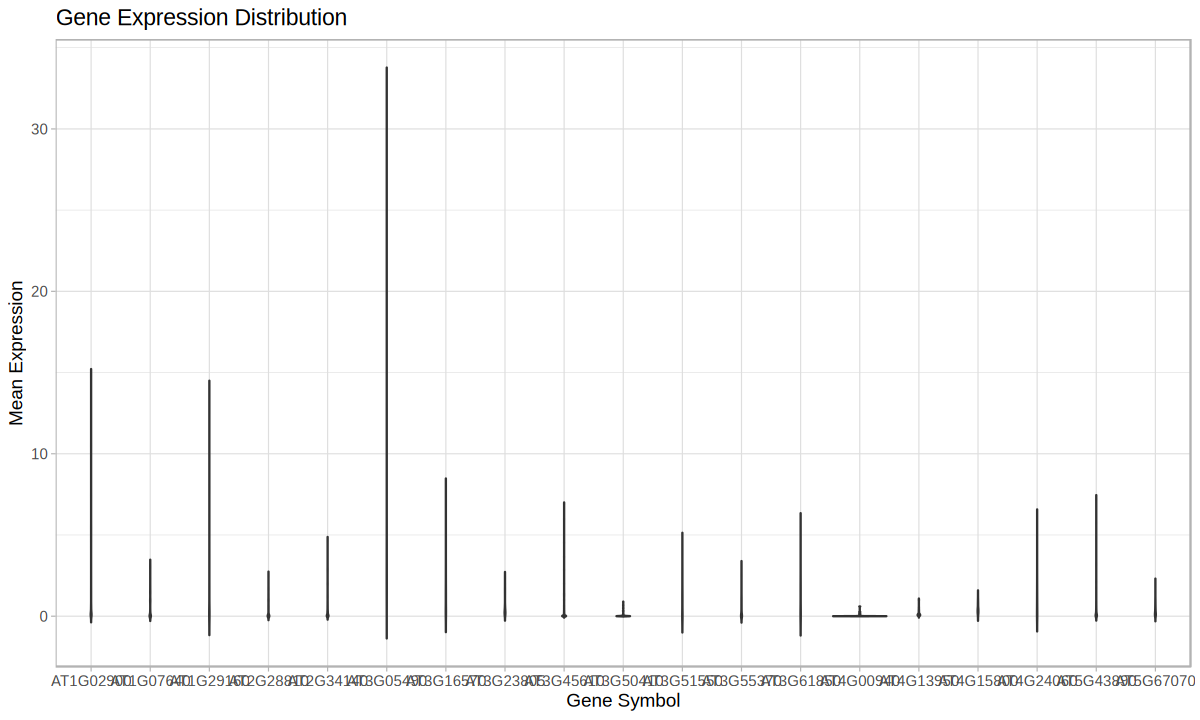

In [37]:
options(repr.plot.width = 10, repr.plot.height = 6)

# Ensure mean_expr is numeric
selected_expr$mean_expr <- as.numeric(selected_expr$mean_expr)

ggplot(selected_expr, aes(x = gene, y = mean_expr, fill = gene)) +
  geom_violin(trim = FALSE, alpha = 0.6) +
  theme_light() +
  labs(
    title = "Gene Expression Distribution",
    x = "Gene Symbol",
    y = "Mean Expression"
  ) +
  theme(legend.position = "none")

### Plot each cell type

In [38]:
DefaultAssay(seu_sub) <- "SCT"

In [39]:
# Extract expression data and metadata
# FetchData pulls the gene values and the specific metadata column
plot_data <- FetchData(seu_sub, vars = c(selected_genes, "time.celltype.anno.Li", "geno"))


In [40]:
# Filter for the first cell type
# Let's say the first one is "T0_Distal_Columella"
#first_type <- unique(plot_data$time.celltype.anno.Li)[1]
#subset_df <- plot_data %>% filter(time.celltype.anno.Li == first_type)

#head(subset_df)

In [41]:
# Reshape data from 'wide' to 'long' for ggplot
plot_long <- plot_data %>%
  pivot_longer(cols = all_of(selected_genes), names_to = "gene", values_to = "expression")

head(plot_long)

time.celltype.anno.Li,geno,gene,expression
<chr>,<chr>,<chr>,<dbl>
Elongation_Procambium,WT,AT3G51550,0.6931472
Elongation_Procambium,WT,AT5G43890,0.0000000
Elongation_Procambium,WT,AT3G16570,0.0000000
Elongation_Procambium,WT,AT1G02900,0.0000000
Elongation_Procambium,WT,AT3G05490,1.6094379
Elongation_Procambium,WT,AT4G15800,1.0986123


In [42]:
# Add common names
gene_map_df <- data.frame(
  gene = c("AT3G51550", "AT5G43890", "AT3G16570", "AT1G02900", "AT3G05490", 
           "AT4G15800", "AT3G23805", "AT4G13950", "AT5G67070", "AT4G24060", 
           "AT3G61850", "AT3G50410", "AT1G07640", "AT3G55370", "AT2G34140", 
           "AT1G29160", "AT3G45610", "AT4G00940", "AT2G28810"),
  common_name = c("FER", "YUC5", "RALF23", "RALF1", "RALF22", 
                  "RALF33", "RALF24", "RALF31", "RALF34", "DOF4.6", 
                  "DAG1", "OBP1", "OBP2", "OBP3", "CDF4", 
                  "COG1", "DOF3.2/6", "DOF4.1", "DOF2.2"),
  stringsAsFactors = FALSE
)

plot_long <- merge(plot_long, gene_map_df, by = "gene")

In [43]:
head(plot_long)

,gene,time.celltype.anno.Li,geno,expression,common_name
,<chr>,<chr>,<chr>,<dbl>,<chr>
1,AT1G02900,Proliferation Domain_Metaphloem & Companion Cell,fer-4,0.0000000,RALF1
2,AT1G02900,Proximal Lateral Root Cap,fer-4,0.6931472,RALF1
3,AT1G02900,Proximal Lateral Root Cap,fer-4,0.0000000,RALF1
4,AT1G02900,Proximal Lateral Root Cap,fer-4,0.0000000,RALF1
5,AT1G02900,Elongation_Xylem Pole Pericycle,fer-4,0.0000000,RALF1
6,AT1G02900,Distal Lateral Root Cap,fer-4,0.0000000,RALF1


In [44]:
plot_long$geno <- factor(x = plot_long$geno, levels = c("WT", "fer-4"))

> Exploratory (NOT USED in the paper): per-cell-type and pooled violins of the selected genes (cells 48-57).

In [45]:
#options(repr.plot.width = 20, repr.plot.height = 6)

#ggplot(plot_long, aes(x = common_name, y = expression, fill = common_name)) +
#  geom_violin(scale = "width", trim = TRUE, alpha = 0.7) +
#  facet_grid(.~ geno) +
#  geom_boxplot(width = 0.1, outlier.shape = NA, fill = "white", alpha = 0.5) +
#  theme_light(base_size = 20) +
 # labs(title = paste("Cell Type:", first_type),
#       x = "",
#       y = "Expression Level") +
#  theme(axis.text.x = element_text(angle = 45, hjust = 1),
 #       strip.text = element_text(size = 25, face = "bold", color = "black"),
 #       strip.background = element_rect(fill = "white"),
 #       legend.position = "none")

In [46]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/Feronia/analysis"

In [47]:
# Plot for every cell type

# 1. Get a list of all unique cell types
cell_types <- unique(plot_long$time.celltype.anno.Li)

# 2. Loop through each cell type and save a PDF
for (ct in cell_types) {
  
  # Filter data for the specific cell type
  subset_data <- plot_long %>% filter(time.celltype.anno.Li == ct)
  
  # Generate the plot
  p <- ggplot(subset_data, aes(x = common_name, y = expression, fill = common_name)) +
    geom_violin(scale = "width", trim = TRUE, alpha = 0.7) +
    facet_grid(. ~ geno) +
    geom_boxplot(width = 0.1, outlier.shape = NA, fill = "white", alpha = 0.5) +
    theme_light(base_size = 20) +
    labs(title = paste("Cell Type:", ct),
         x = "",
         y = "Expression Level") +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1),
      strip.text = element_text(size = 25, face = "bold", color = "black"),
      strip.background = element_rect(fill = "white"),
      legend.position = "none"
    )
  
  # Create a safe filename (replaces spaces/slashes with underscores)
  safe_name <- gsub("[ /&]", "_", ct)
  file_path <- paste0("20260209_violin_plots/20260209_feronia_violin_", safe_name, ".pdf")
  
  # Save the plot
  ggsave(file_path, plot = p, width = 20, height = 6, device = "pdf")
  
  message(paste("Saved:", file_path))
}

Saved: 20260209_violin_plots/20260209_feronia_violin_Proliferation_Domain_Metaphloem___Companion_Cell.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Proximal_Lateral_Root_Cap.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Elongation_Xylem_Pole_Pericycle.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Distal_Lateral_Root_Cap.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Elongation_Metaxylem.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Maturation_Endodermis.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Elongation_Procambium.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Elongation_Phloem_Pole_Pericycle.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Distal_Columella.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Elongation_Atrichoblast.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Elongation_Protoxylem.pdf

Saved: 20260209_violin_plots/20260209_feronia_violin_Elongation_Tricho

### All cell types pooled


In [48]:
# Extract expression data and metadata
# FetchData pulls the gene values and the specific metadata column
plot_data <- FetchData(seu_sub, vars = c(selected_genes, "geno"))


In [49]:
# Reshape data from 'wide' to 'long' for ggplot
plot_long <- plot_data %>%
  pivot_longer(cols = all_of(selected_genes), names_to = "gene", values_to = "expression")

head(plot_long)

geno,gene,expression
<chr>,<chr>,<dbl>
WT,AT3G51550,0.6931472
WT,AT5G43890,0.0000000
WT,AT3G16570,0.0000000
WT,AT1G02900,0.0000000
WT,AT3G05490,1.6094379
WT,AT4G15800,1.0986123


In [50]:
plot_long <- merge(plot_long, gene_map_df, by = "gene")

In [51]:
head(plot_long)

,gene,geno,expression,common_name
,<chr>,<chr>,<dbl>,<chr>
1,AT1G02900,fer-4,0.0000000,RALF1
2,AT1G02900,fer-4,0.6931472,RALF1
3,AT1G02900,fer-4,0.0000000,RALF1
4,AT1G02900,fer-4,0.0000000,RALF1
5,AT1G02900,fer-4,0.0000000,RALF1
6,AT1G02900,fer-4,0.0000000,RALF1


In [52]:
plot_long$geno <- factor(x = plot_long$geno, levels = c("WT", "fer-4"))

In [53]:
# Generate the plot
p <- ggplot(plot_long, aes(x = common_name, y = expression, fill = common_name)) +
  geom_violin(scale = "width", trim = TRUE, alpha = 0.7) +
  facet_grid(. ~ geno) +
  geom_boxplot(width = 0.1, outlier.shape = NA, fill = "white", alpha = 0.5) +
  theme_light(base_size = 20) +
  labs(x = "",
       y = "Expression Level") +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 25, face = "bold", color = "black"),
    strip.background = element_rect(fill = "white"),
    legend.position = "none"
  )

# Create a safe filename (replaces spaces/slashes with underscores)
file_path <- paste0("20260209_violin_plots/20260209_feronia_violin_all_celltypes_pooled.pdf")

# Save the plot
ggsave(file_path, plot = p, width = 20, height = 6, device = "pdf")


### Plot each gene

In [54]:
DefaultAssay(seu_sub) <- "SCT"

In [55]:
# Extract expression data and metadata
# FetchData pulls the gene values and the specific metadata column
plot_data <- FetchData(seu_sub, vars = c(selected_genes, "time.celltype.anno.Li", "geno"))


In [56]:
head(plot_data, 3)

,AT3G51550,AT5G43890,AT3G16570,AT1G02900,AT3G05490,AT4G15800,AT3G23805,AT4G13950,AT5G67070,AT4G24060,⋯,AT3G50410,AT1G07640,AT3G55370,AT2G34140,AT1G29160,AT3G45610,AT4G00940,AT2G28810,time.celltype.anno.Li,geno
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
AAACCCAAGGACTTCT_4,0.6931472,0,0.0000000,0.000000,1.609438,1.098612,0,0,0,0,⋯,0,0,0,0,0,0,0,0,Elongation_Procambium,WT
AAACCCAAGGTCGTGA_4,1.7917595,0,0.6931472,0.000000,1.098612,0.000000,0,0,0,0,⋯,0,0,0,0,0,0,0,0,Transition Domain_Trichoblast,WT
AAACCCAAGTGCACTT_4,1.3862944,0,0.0000000,1.098612,1.609438,0.000000,0,0,0,0,⋯,0,0,0,0,0,0,0,0,Transition Domain_Trichoblast,WT


In [57]:
sum(is.na(plot_data))

[1] 0

In [58]:
# Reshape data from 'wide' to 'long' for ggplot
plot_long <- plot_data %>%
  pivot_longer(cols = all_of(selected_genes), names_to = "gene", values_to = "expression")

head(plot_long)

time.celltype.anno.Li,geno,gene,expression
<chr>,<chr>,<chr>,<dbl>
Elongation_Procambium,WT,AT3G51550,0.6931472
Elongation_Procambium,WT,AT5G43890,0.0000000
Elongation_Procambium,WT,AT3G16570,0.0000000
Elongation_Procambium,WT,AT1G02900,0.0000000
Elongation_Procambium,WT,AT3G05490,1.6094379
Elongation_Procambium,WT,AT4G15800,1.0986123


In [59]:
# Add common names
gene_map_df <- data.frame(
  gene = c("AT3G51550", "AT5G43890", "AT3G16570", "AT1G02900", "AT3G05490", 
           "AT4G15800", "AT3G23805", "AT4G13950", "AT5G67070", "AT4G24060", 
           "AT3G61850", "AT3G50410", "AT1G07640", "AT3G55370", "AT2G34140", 
           "AT1G29160", "AT3G45610", "AT4G00940", "AT2G28810"),
  common_name = c("FER", "YUC5", "RALF23", "RALF1", "RALF22", 
                  "RALF33", "RALF24", "RALF31", "RALF34", "DOF4.6", 
                  "DAG1", "OBP1", "OBP2", "OBP3", "CDF4", 
                  "COG1", "DOF3.2/6", "DOF4.1", "DOF2.2"),
  stringsAsFactors = FALSE
)

plot_long <- merge(plot_long, gene_map_df, by = "gene")

In [60]:
plot_long$geno <- factor(x = plot_long$geno, levels = c("WT", "fer-4"))

> Exploratory (NOT USED in the paper): cells 66-69 are checks and a first per-gene version; cell 70 below is the one used.

In [61]:
plot_long_sub <- plot_long %>% filter(gene  == "AT4G15800")

In [62]:
head(plot_long_sub)

,gene,time.celltype.anno.Li,geno,expression,common_name
,<chr>,<chr>,<fct>,<dbl>,<chr>
1,AT4G15800,Proximal Columella,fer-4,0.000000,RALF33
2,AT4G15800,Maturation_Trichoblast,fer-4,1.386294,RALF33
3,AT4G15800,Proximal Columella,fer-4,0.000000,RALF33
4,AT4G15800,Proximal Lateral Root Cap,fer-4,1.098612,RALF33
5,AT4G15800,Elongation_Atrichoblast,fer-4,0.000000,RALF33
6,AT4G15800,Transition Domain_Trichoblast,fer-4,1.098612,RALF33


In [64]:
# Loop over each unique gene ID
for (g in unique(plot_long$gene)) {
  
  # Filter data for the specific gene
  plot_long_sub <- plot_long %>% filter(gene == g)
  
  # Get the common name for the title
  this_name <- unique(plot_long_sub$common_name)
  
  # Generate the plot
  p <- ggplot(plot_long_sub, aes(x = time.celltype.anno.Li, y = expression, fill = geno)) +
    geom_violin(scale = "width", trim = TRUE, alpha = 0.7, position = position_dodge(width = 0.9)) + 
    theme_light(base_size = 20) +
    labs(title = this_name,
         x = "",
         y = "Expression Level",
         fill = "") +
    theme(
      plot.title = element_text(hjust = 0.5, face = "bold"),
      axis.text.x = element_text(angle = 45, hjust = 1),
      strip.text = element_text(size = 25, face = "bold", color = "black"),
      strip.background = element_rect(fill = "white"),
      legend.position = "none",
      panel.grid.minor.y = element_blank(),
      panel.grid.major.y = element_blank(),
      panel.grid.major.x = element_blank(),
      # Generous bottom margin for long cell type names
      plot.margin = margin(t = 20, r = 20, b = 80, l = 80)
    )

  # Define file path using the gene ID or common name
  file_path <- paste0("20260209_violin_plots/20260209_feronia_violin_", g, ".pdf")
  
  # Save the plot with a wide aspect ratio to prevent squeezing
  ggsave(file_path, plot = p, width = 30, height = 10, device = "pdf", limitsize = FALSE)
  
  # Optional: Print progress to console
  message(paste("Saved plot for:", this_name))
}

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Saved plot for: RALF1

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Saved plot for: OBP2

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Saved plot for: COG1

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Saved plot for: DOF2.2

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Saved plot for: CDF4

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such

In [66]:
plot_long %>% filter(common_name == "OBP3") %>% filter(time.celltype.anno.Li == "Proliferation Domain_Procambium")

gene,time.celltype.anno.Li,geno,expression,common_name
<chr>,<chr>,<fct>,<dbl>,<chr>
AT3G55370,Proliferation Domain_Procambium,fer-4,0.0000000,OBP3
AT3G55370,Proliferation Domain_Procambium,fer-4,0.6931472,OBP3
AT3G55370,Proliferation Domain_Procambium,fer-4,1.0986123,OBP3
AT3G55370,Proliferation Domain_Procambium,fer-4,0.0000000,OBP3


> **USED IN THE PAPER: Extended Data Fig. 5e** (violin plot of *YUC5*, gene AT5G43890, per cell-type/stage cluster, WT vs *fer-4*, SCT `data`). This loop writes one PDF per gene; the *YUC5* one is `20260209_violin_plots/20260209_feronia_violin_AT5G43890.pdf`. It overwrites the files of the previous cell (68).

In [67]:
# Loop over each unique gene ID
for (g in unique(plot_long$gene)) {
  
  # 1. Filter and Complete missing combinations
  plot_long_sub <- plot_long %>% 
    filter(gene == g) %>%
    # This creates rows for every x-axis category/genotype combo not present in the data
    complete(time.celltype.anno.Li, geno, fill = list(expression = 0)) %>%
    # Re-fill the gene and common_name columns which become NA after complete()
    mutate(gene = g, 
           common_name = unique(na.omit(common_name))[1])
  
  # Get the common name for the title
  this_name <- unique(plot_long_sub$common_name)
  
  # 2. Generate the plot
  p <- ggplot(plot_long_sub, aes(x = time.celltype.anno.Li, y = expression, fill = geno)) +
    geom_violin(scale = "width", trim = TRUE, alpha = 0.7, position = position_dodge(width = 0.9), drop = FALSE) + 
    theme_light(base_size = 24) +
    labs(title = this_name,
         x = "",
         y = "Expression Level",
         fill = "Genotype") +
    theme(
      plot.title = element_text(hjust = 0.5, face = "bold"),
      axis.text.x = element_text(angle = 45, hjust = 1),
      strip.text = element_text(size = 30, face = "bold", color = "black"),
      strip.background = element_rect(fill = "white"),
      panel.grid.minor.y = element_blank(),
      panel.grid.major.y = element_blank(),
      panel.grid.major.x = element_blank(),
      # Increased bottom margin slightly for the rotated labels
      plot.margin = margin(t = 20, r = 20, b = 80, l = 80)
    )

  # 3. Define file path and save
  file_path <- paste0("20260209_violin_plots/20260209_feronia_violin_", g, ".pdf")
  
  ggsave(file_path, plot = p, width = 40, height = 10, device = "pdf", limitsize = FALSE)
  
  message(paste("Saved plot for:", this_name))
}

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: RALF1

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: OBP2

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: COG1

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: DOF2.2

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: CDF4

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: RALF22

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: RALF23

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: RALF24

Warning message:
“Cannot compute density for groups with fewer than two datapoints.”
Saved plot for: DOF3.2/6

Warning message:
“Cannot

## UMAPs

In [24]:
seu_sub

An object of class Seurat 
72086 features across 44664 samples within 3 assays 
Active assay: integrated (17768 features, 17768 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, SCT
 4 dimensional reductions calculated: pca, umap, umap_3D, umap_2D

In [25]:
DefaultAssay(seu_sub) <- "SCT"

In [26]:
seu_sub

An object of class Seurat 
72086 features across 44664 samples within 3 assays 
Active assay: SCT (24907 features, 0 variable features)
 3 layers present: counts, data, scale.data
 2 other assays present: RNA, integrated
 4 dimensional reductions calculated: pca, umap, umap_3D, umap_2D

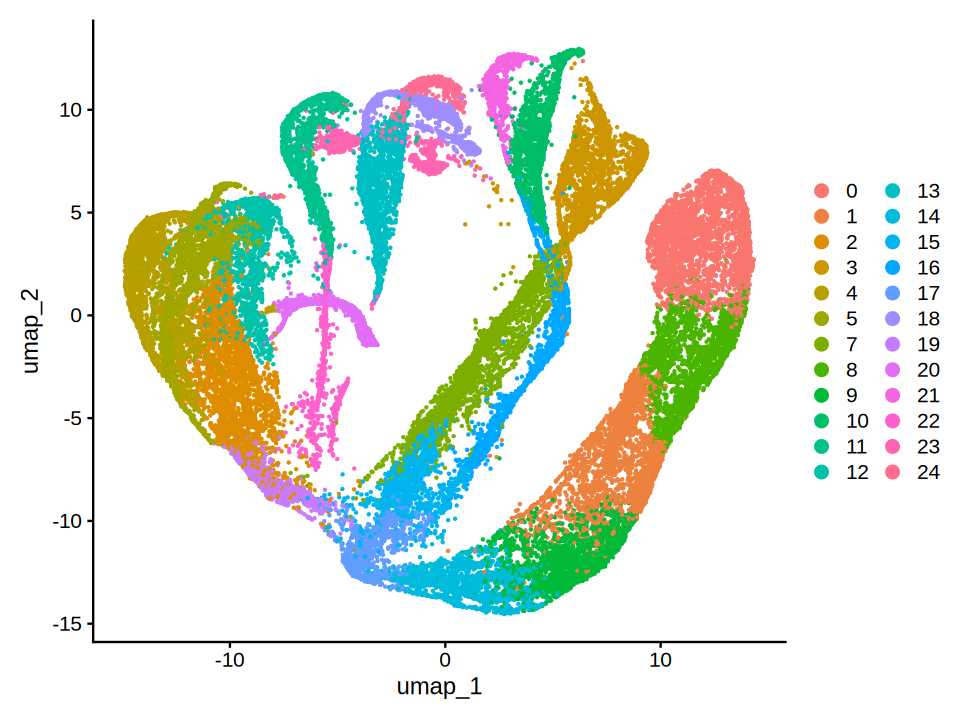

In [27]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seu_sub, reduction = "umap")

In [28]:
head(seu_sub, 3)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype,geno,date
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<fct>,<chr>,<chr>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.1071046,7949,⋯,NA,NA,NA,NA,4,Elongation,Procambium,WT,WT,1
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.3690037,9904,⋯,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT,WT,1
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.3273322,8348,⋯,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT,WT,1


In [29]:
# Gene list from Michelle
selected_genes <- c("AT3G51550", "AT5G43890", "AT3G16570", "AT1G02900", "AT3G05490", "AT4G15800",
                    "AT3G23805", "AT4G13950", "AT5G67070", "AT4G24060", "AT3G61850", "AT3G50410",
                    "AT1G07640", "AT3G55370", "AT2G34140", "AT1G29160", "AT3G45610", "AT4G00940",
                    "AT2G28810")

length(selected_genes)

[1] 19

In [30]:
seu_sub$geno <- factor(seu_sub$geno, levels = c("WT", "fer-4"))

In [31]:
# Add common names
gene_map_df <- data.frame(
  gene = c("AT3G51550", "AT5G43890", "AT3G16570", "AT1G02900", "AT3G05490", 
           "AT4G15800", "AT3G23805", "AT4G13950", "AT5G67070", "AT4G24060", 
           "AT3G61850", "AT3G50410", "AT1G07640", "AT3G55370", "AT2G34140", 
           "AT1G29160", "AT3G45610", "AT4G00940", "AT2G28810"),
  common_name = c("FER", "YUC5", "RALF23", "RALF1", "RALF22", 
                  "RALF33", "RALF24", "RALF31", "RALF34", "DOF4.6", 
                  "DAG1", "OBP1", "OBP2", "OBP3", "CDF4", 
                  "COG1", "DOF3.2/6", "DOF4.1", "DOF2.2"),
  stringsAsFactors = FALSE
)


Warning message:
“A numeric `legend.position` argument in `theme()` was deprecated in ggplot2 3.5.0.
ℹ Please use the `legend.position.inside` argument of `theme()` instead.”


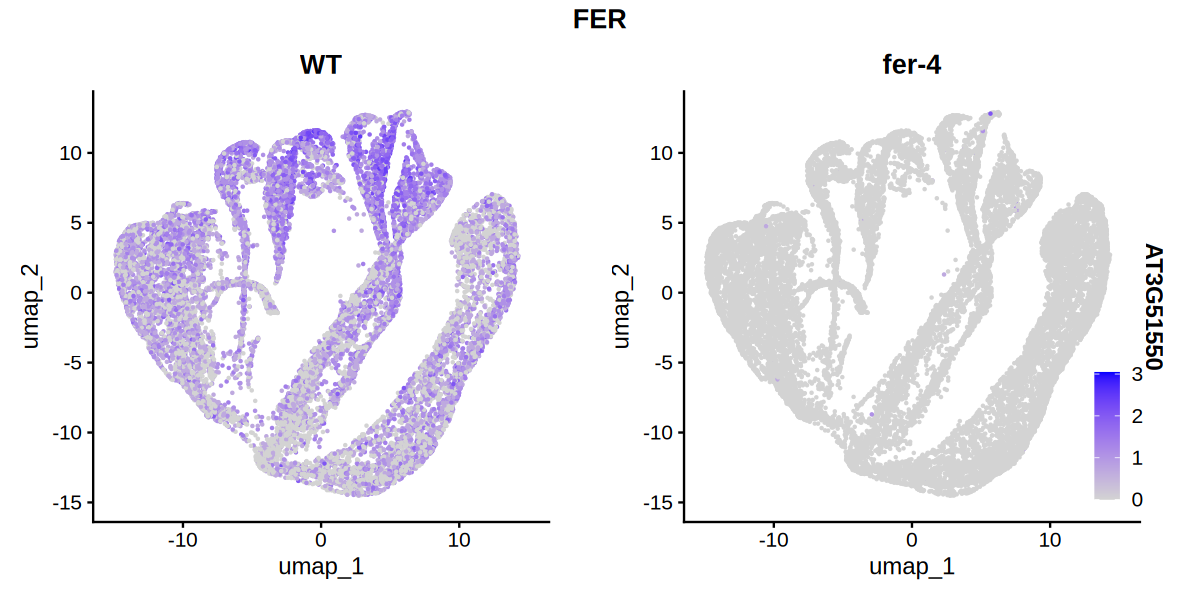

In [32]:
options(repr.plot.width = 10, repr.plot.height = 5)

# 1. Extract the current gene ID
current_gene <- selected_genes[1]

# 2. Find the corresponding common name from your data frame
# We use match() to ensure we get the specific name for this gene
display_name <- gene_map_df$common_name[match(current_gene, gene_map_df$gene)]

# 3. Create a combined title
#full_title <- paste0(display_name, " (", current_gene, ")")
full_title <- display_name

# 4. Generate the plot
p <- FeaturePlot(
  seu_sub, features = current_gene,
  reduction = "umap", 
  split.by = "geno", 
  ncol = 2
) + theme(legend.position = c(0.9,0.2))

# 5. Apply the common name as the main title
p + plot_annotation(
  title = full_title,
  theme = theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
)

> **USED IN THE PAPER: Extended Data Fig. 5d** (UMAP coloured by *YUC5* expression, WT | *fer-4*). The *YUC5* file is `20260224_umap/20260224_feronia_umap_AT5G43890.pdf`.

In [108]:
# Loop over each unique gene ID
# Using your 'gene_map_df' to drive the loop ensures we have names for everything
for (g in gene_map_df$gene) {
  
  # 1. Get the common name for the current gene
  this_name <- gene_map_df$common_name[match(g, gene_map_df$gene)]
  
  # 2. Generate the FeaturePlot
  # We use 'g' for the feature and 'this_name' for the title
  p_base <- FeaturePlot(
    seu_sub, 
    features = g,
    reduction = "umap", 
    split.by = "geno", 
    ncol = 2,
    pt.size = 3,
    raster = TRUE,      # Converts the cell points to a bitmap
    raster.dpi = c(900, 900) # Keeps points high-resolution (standard for publication)
  ) + theme(legend.position = c(0.9,0.2))
  
  # 3. Apply the theme cleaning (Remove right-side gene name and panel titles)
  p_cleaned <- p_base & NoAxes() & theme(
    plot.tag = element_blank(),
    plot.tag.position = "none",
    legend.title = element_blank()
  )
  
  # 4. Add the centered common name title
  p_final <- p_cleaned + plot_annotation(
    title = this_name,
    theme = theme(plot.title = element_text(hjust = 0.5, size = 15, face = "bold"))
  )
  
  # 5. Define file path and save
  # Using the gene ID in the filename for uniqueness
  file_path <- paste0("20260224_umap/20260224_feronia_umap_", g, ".pdf")
  
  # Saving with dimensions that match your 10:5 aspect ratio
  ggsave(file_path, plot = p_final, width = 10, height = 5, device = "pdf", useDingbats = FALSE)
  
  message(paste("Saved plot for:", this_name, "(", g, ")"))
}

Saved plot for: FER ( AT3G51550 )

Saved plot for: YUC5 ( AT5G43890 )

Saved plot for: RALF23 ( AT3G16570 )

Saved plot for: RALF1 ( AT1G02900 )

Saved plot for: RALF22 ( AT3G05490 )

Saved plot for: RALF33 ( AT4G15800 )

Saved plot for: RALF24 ( AT3G23805 )

Saved plot for: RALF31 ( AT4G13950 )

Saved plot for: RALF34 ( AT5G67070 )

Saved plot for: DOF4.6 ( AT4G24060 )

Saved plot for: DAG1 ( AT3G61850 )

Saved plot for: OBP1 ( AT3G50410 )

Saved plot for: OBP2 ( AT1G07640 )

Saved plot for: OBP3 ( AT3G55370 )

Saved plot for: CDF4 ( AT2G34140 )

Saved plot for: COG1 ( AT1G29160 )

Saved plot for: DOF3.2/6 ( AT3G45610 )

Saved plot for: DOF4.1 ( AT4G00940 )

Saved plot for: DOF2.2 ( AT2G28810 )



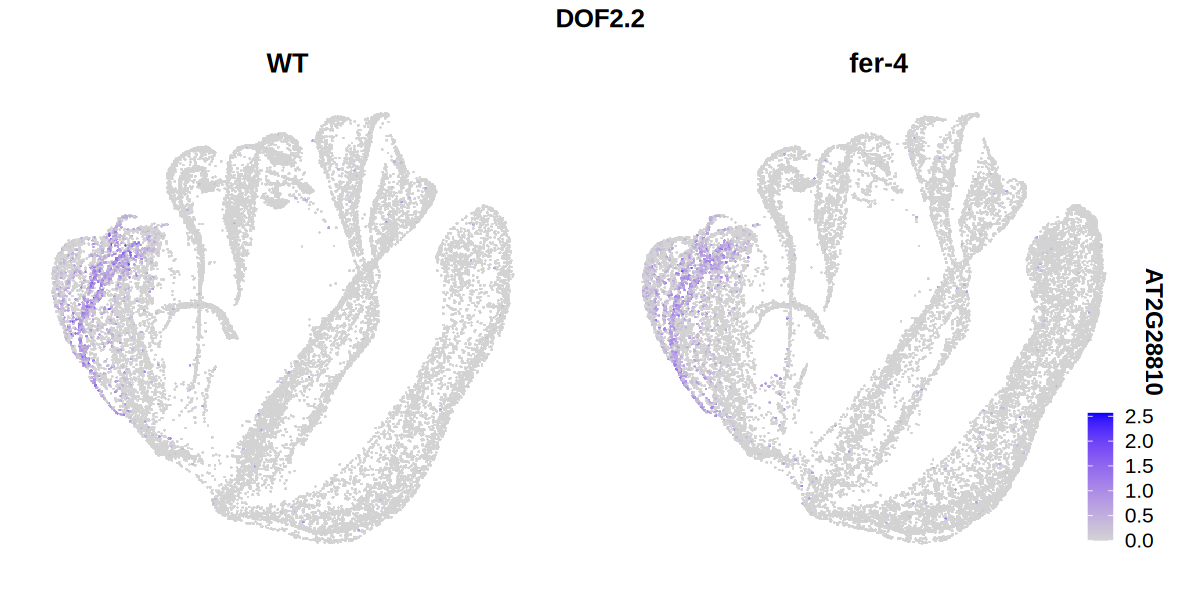

In [110]:
p_final